# 05 · Text mining: sentiment and topics (SCRUM-28)

Shows the outputs of `python3 src/text_mining.py` (run it first to refresh them): VADER sentiment and LDA topics of the YouTube comment corpus (`data/processed/text_corpus.csv`, SCRUM-23). Method, parameters and limitations are in `docs/text_mining.md`.

**Descriptive only.** The comments were collected on 2026-10-03/04, so these numbers describe that October sample. They are not time-series predictors; for modelling use SCRUM-24's leak-free `processed/method2_*` files.

Each finding below is computed from the data when the notebook runs.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
P = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
comments = pd.read_csv(P / "text_sentiment_comments.csv", dtype={"comment_id": str})
sent = pd.read_csv(P / "text_sentiment_by_product.csv")
groups = pd.read_csv(P / "text_mining_by_group.csv")
terms = pd.read_csv(P / "text_topics_terms.csv")
link = pd.read_csv(P / "text_signal_link.csv")
types = groups[groups["group_type"] == "product_type"].set_index("group")
brands = groups[groups["group_type"] == "brand"].set_index("group")
lda = terms[terms["method"] == "lda"].drop_duplicates("topic").set_index("topic")


def finding(text):
    display(Markdown(f"**Finding:** {text}"))


unique = comments.drop_duplicates("comment_id")
scored = unique[unique["sentiment_compound"].notna()]
print(f"{len(comments):,} corpus rows, {len(unique):,} unique comments, {len(scored):,} scored, "
      f"{sent['scored_comments'].gt(0).sum()} products with scored comments")

29,189 corpus rows, 26,400 unique comments, 20,317 scored, 60 products with scored comments


## 1. Sentiment distribution

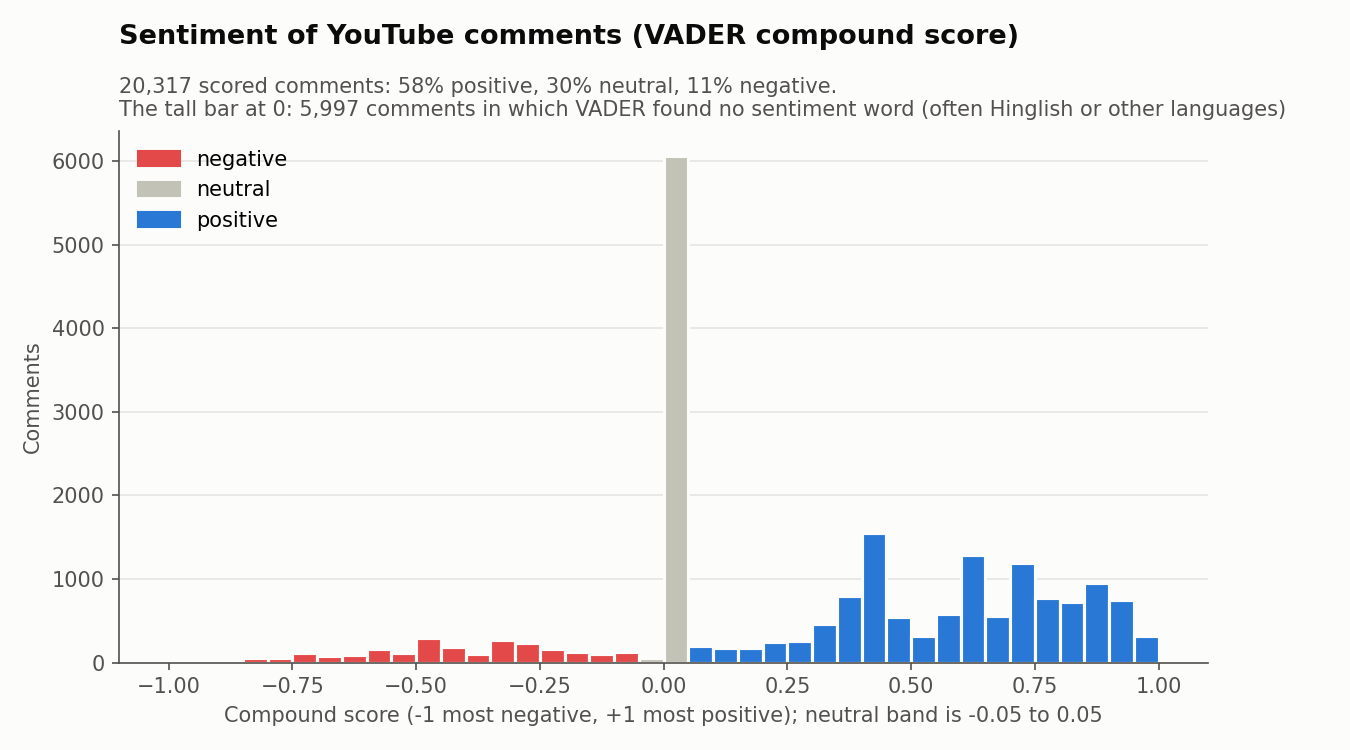

**Finding:** 58% of 20,317 scored comments are positive and 11% negative. 30% score exactly 0, which is 98% of the neutral comments: 'neutral' here mostly means VADER found no English sentiment word (Hinglish, Indonesian), not a neutral opinion.

In [2]:
display(Image(FIG / "text_sentiment_distribution.png"))
share = scored["sentiment_label"].value_counts(normalize=True)
zero = (scored["sentiment_compound"] == 0).mean()
finding(f"{share['positive']:.0%} of {len(scored):,} scored comments are positive and {share['negative']:.0%} "
        f"negative. {zero:.0%} score exactly 0, which is {zero / share['neutral']:.0%} of the neutral comments: "
        "'neutral' here mostly means VADER found no English sentiment word (Hinglish, Indonesian), "
        "not a neutral opinion.")

## 2. Sentiment by product cohort

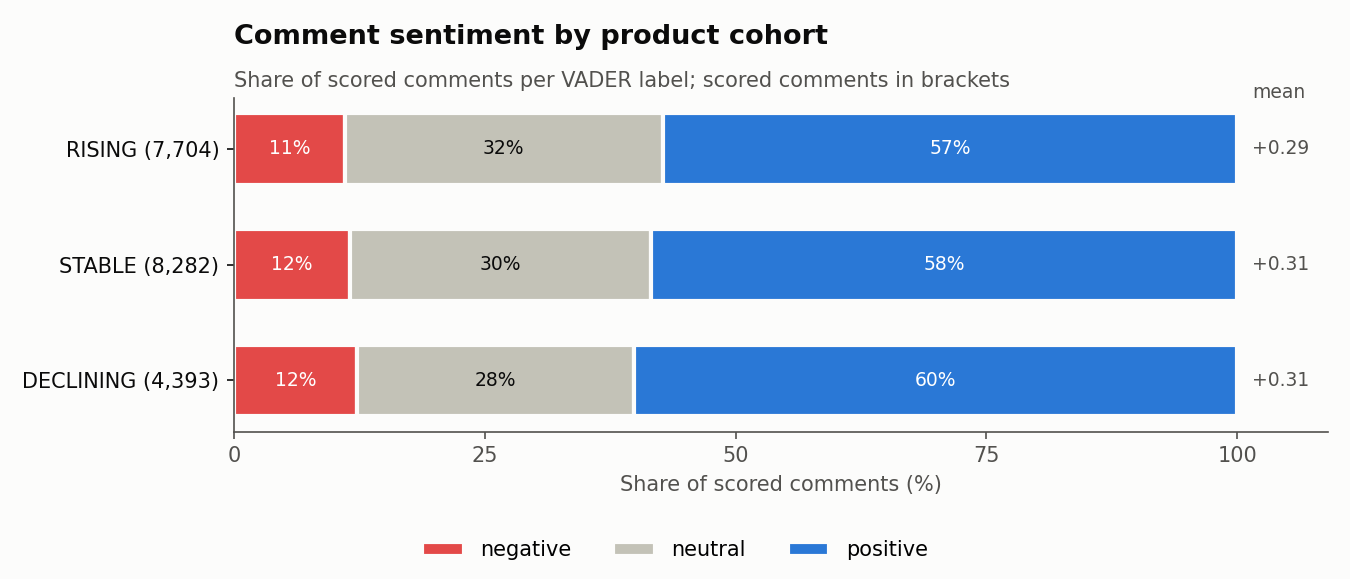

**Finding:** DECLINING comments are the most positive (mean +0.31) and RISING the least (+0.29): a gap of 0.02, while product means inside one cohort span 0.18 to 0.22.

In [3]:
display(Image(FIG / "text_sentiment_by_product_type.png"))
m = types["mean_compound"]
within = sent.groupby("product_type")["mean_compound"].agg(["min", "max"])
finding(f"{m.idxmax()} comments are the most positive (mean {m.max():+.2f}) and {m.idxmin()} the least "
        f"({m.min():+.2f}): a gap of {m.max() - m.min():.2f}, while product means inside one cohort span "
        f"{(within['max'] - within['min']).min():.2f} to {(within['max'] - within['min']).max():.2f}.")

## 3. Sentiment by brand

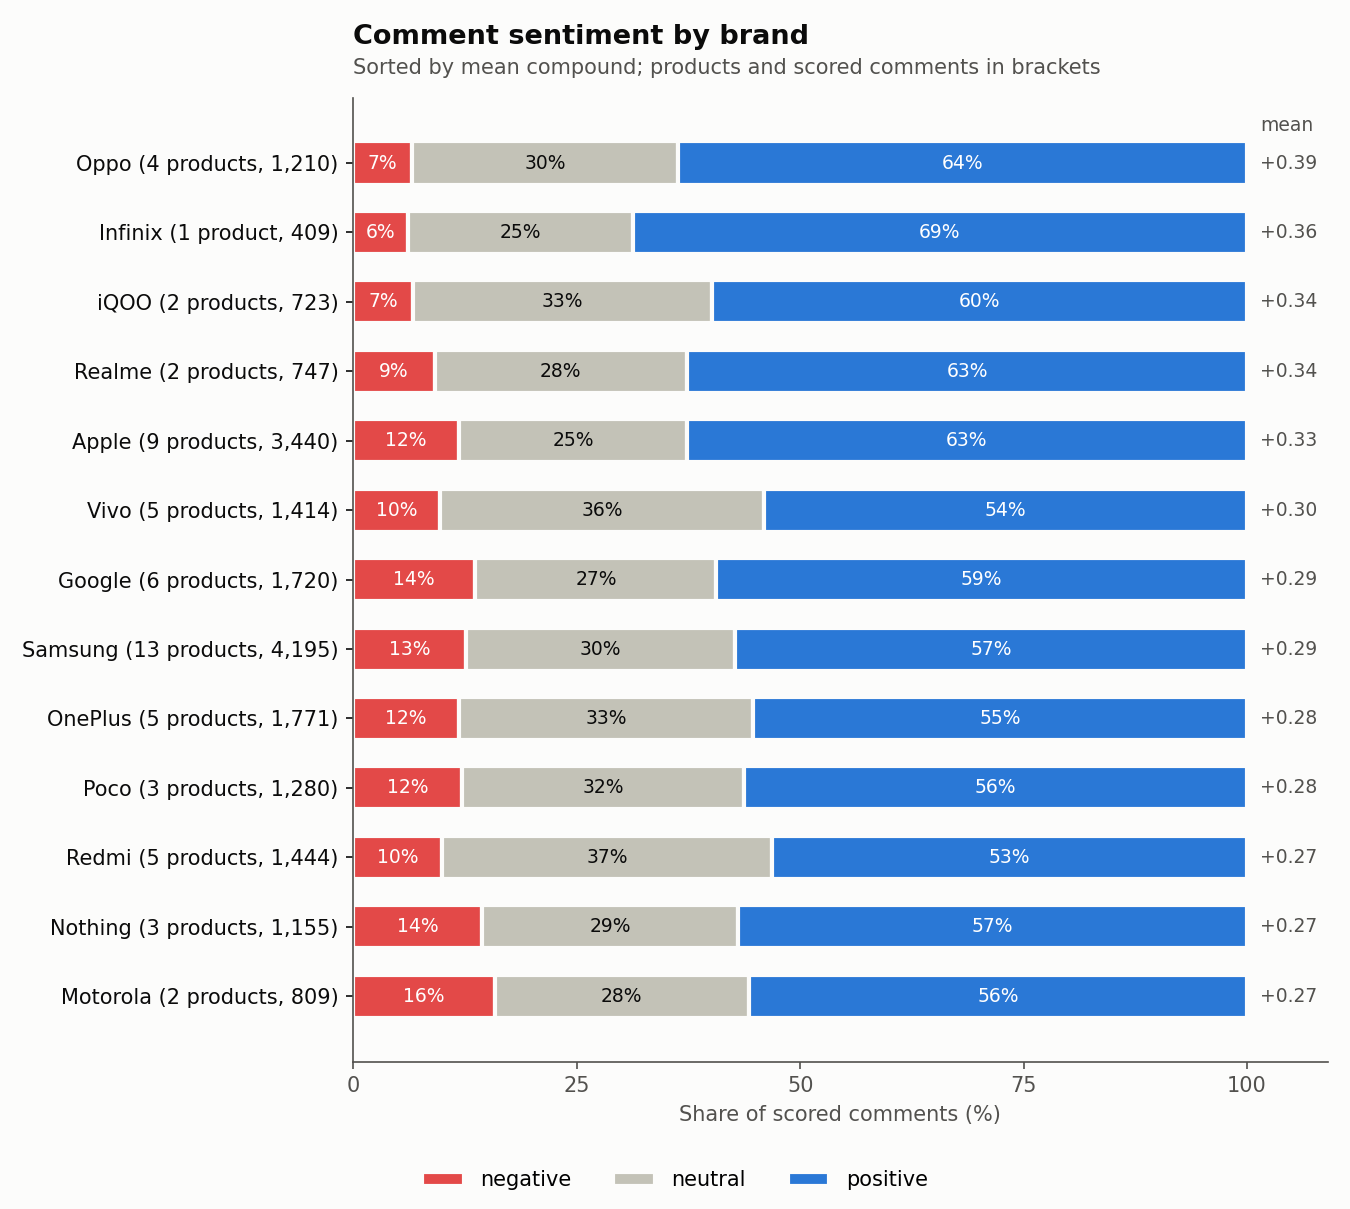

**Finding:** Oppo has the most positive comments (+0.39, 4 products) and Motorola the least (+0.27, 2 products); brands with 1-2 products rest on a few videos.

In [4]:
display(Image(FIG / "text_sentiment_by_brand.png"))
b = brands.sort_values("mean_compound")
finding(f"{b.index[-1]} has the most positive comments ({b['mean_compound'].iloc[-1]:+.2f}, "
        f"{b['products'].iloc[-1]} products) and {b.index[0]} the least ({b['mean_compound'].iloc[0]:+.2f}, "
        f"{b['products'].iloc[0]} products); brands with 1-2 products rest on a few videos.")

## 4. Most and least positive products

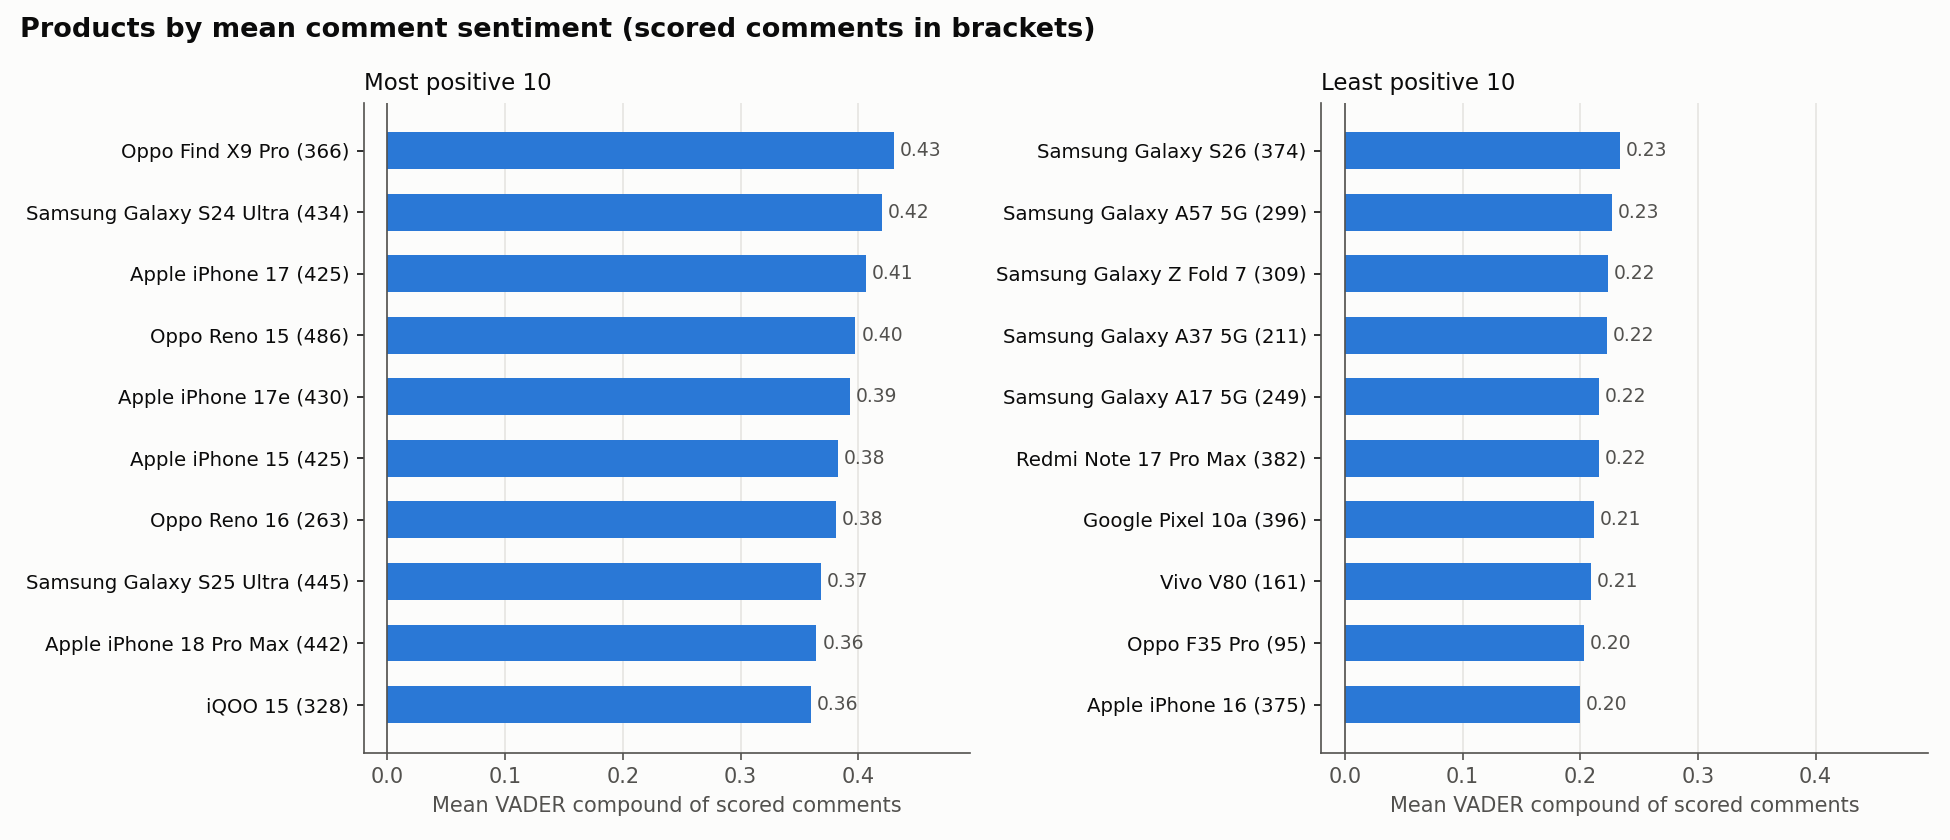

**Finding:** Oppo Find X9 Pro has the most positive comments (+0.43) and Apple iPhone 16 the least (+0.20); 100% of products have a positive mean.

In [5]:
display(Image(FIG / "text_sentiment_top_bottom_products.png"))
r = sent.dropna(subset=["mean_compound"]).sort_values("mean_compound")
finding(f"{r['product_name'].iloc[-1]} has the most positive comments ({r['mean_compound'].iloc[-1]:+.2f}) "
        f"and {r['product_name'].iloc[0]} the least ({r['mean_compound'].iloc[0]:+.2f}); "
        f"{(r['mean_compound'] > 0).mean():.0%} of products have a positive mean.")

## 5. Topics (LDA): top terms

Labels are keyword-based suggestions; confirm them by reading the terms.

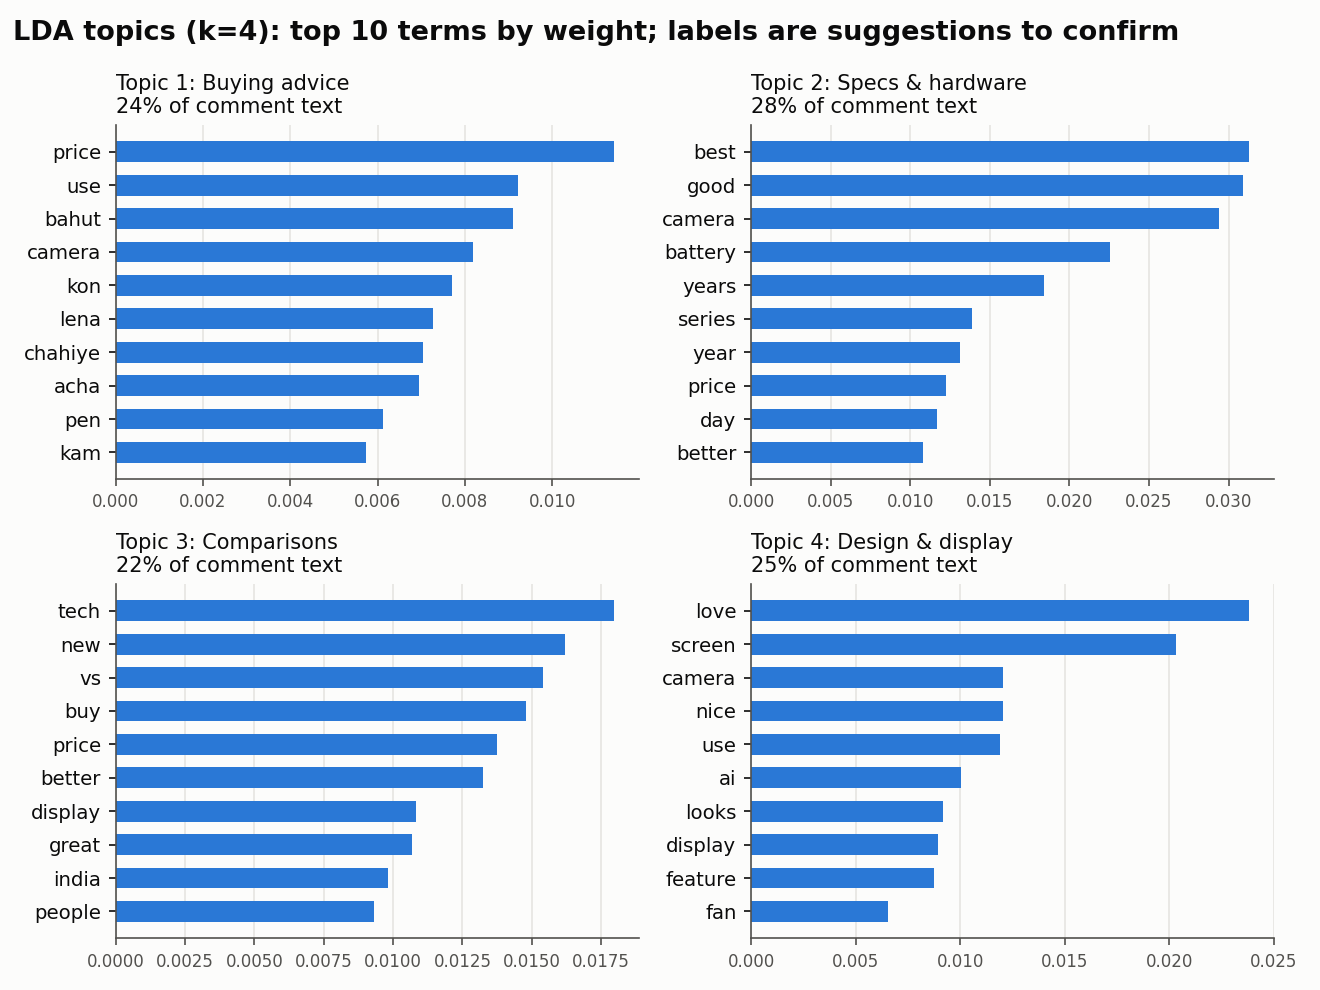

**Finding:** 4 topics; the largest is topic 2 (Specs & hardware, 28% of comment text). Suggested labels: 1: Buying advice; 2: Specs & hardware; 3: Comparisons; 4: Design & display.

In [6]:
display(Image(FIG / "text_topic_terms.png"))
big = lda["topic_mean_share"].idxmax()
finding(f"{len(lda)} topics; the largest is topic {big} ({lda.loc[big, 'label_suggestion']}, "
        f"{lda.loc[big, 'topic_mean_share']:.0%} of comment text). Suggested labels: "
        + "; ".join(f"{t}: {r.label_suggestion}" for t, r in lda.iterrows()) + ".")

## 6. Topic share by product cohort

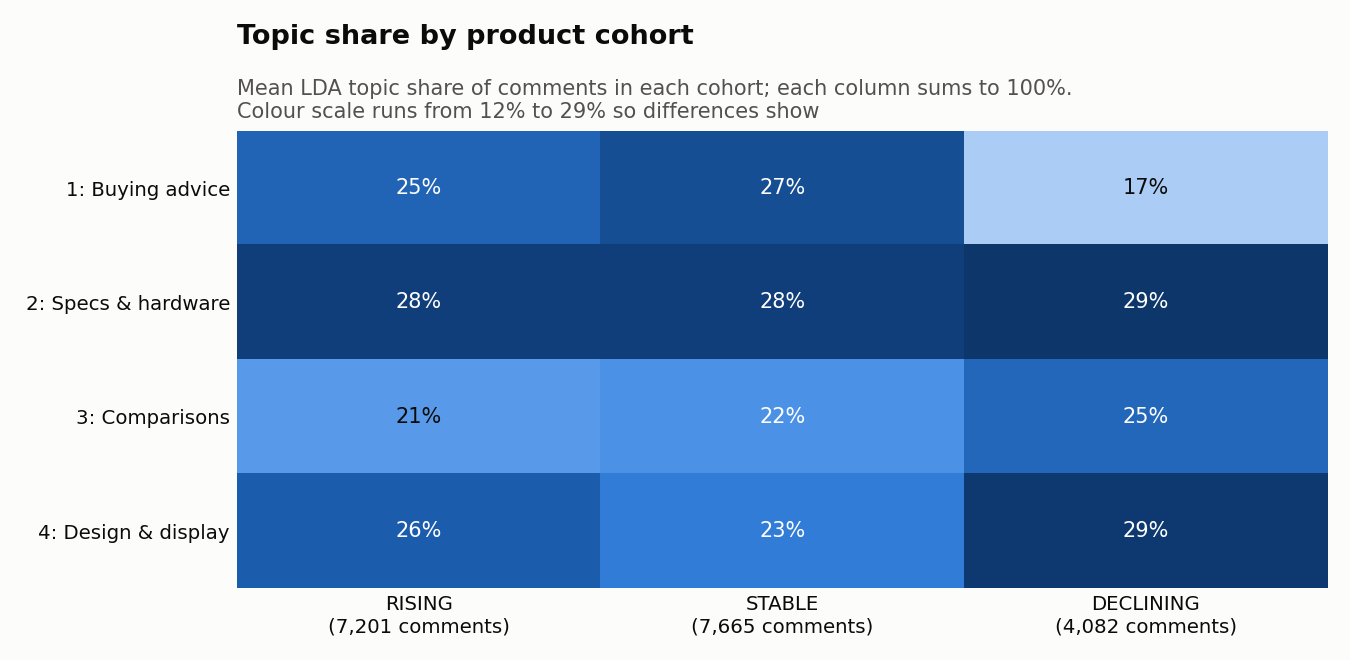

**Finding:** Topic 1 (Buying advice) differs most between cohorts: 27% in STABLE vs 17% in DECLINING.

In [7]:
display(Image(FIG / "text_topic_share_by_product_type.png"))
cols = [f"topic_{t}_share" for t in lda.index]
spread = types[cols].max() - types[cols].min()
col = spread.idxmax(); t = int(col.split("_")[1])
finding(f"Topic {t} ({lda.loc[t, 'label_suggestion']}) differs most between cohorts: "
        f"{types[col].max():.0%} in {types[col].idxmax()} vs {types[col].min():.0%} in {types[col].idxmin()}.")

## 7. Sentiment and search interest

One dot per product; descriptive, not causal.

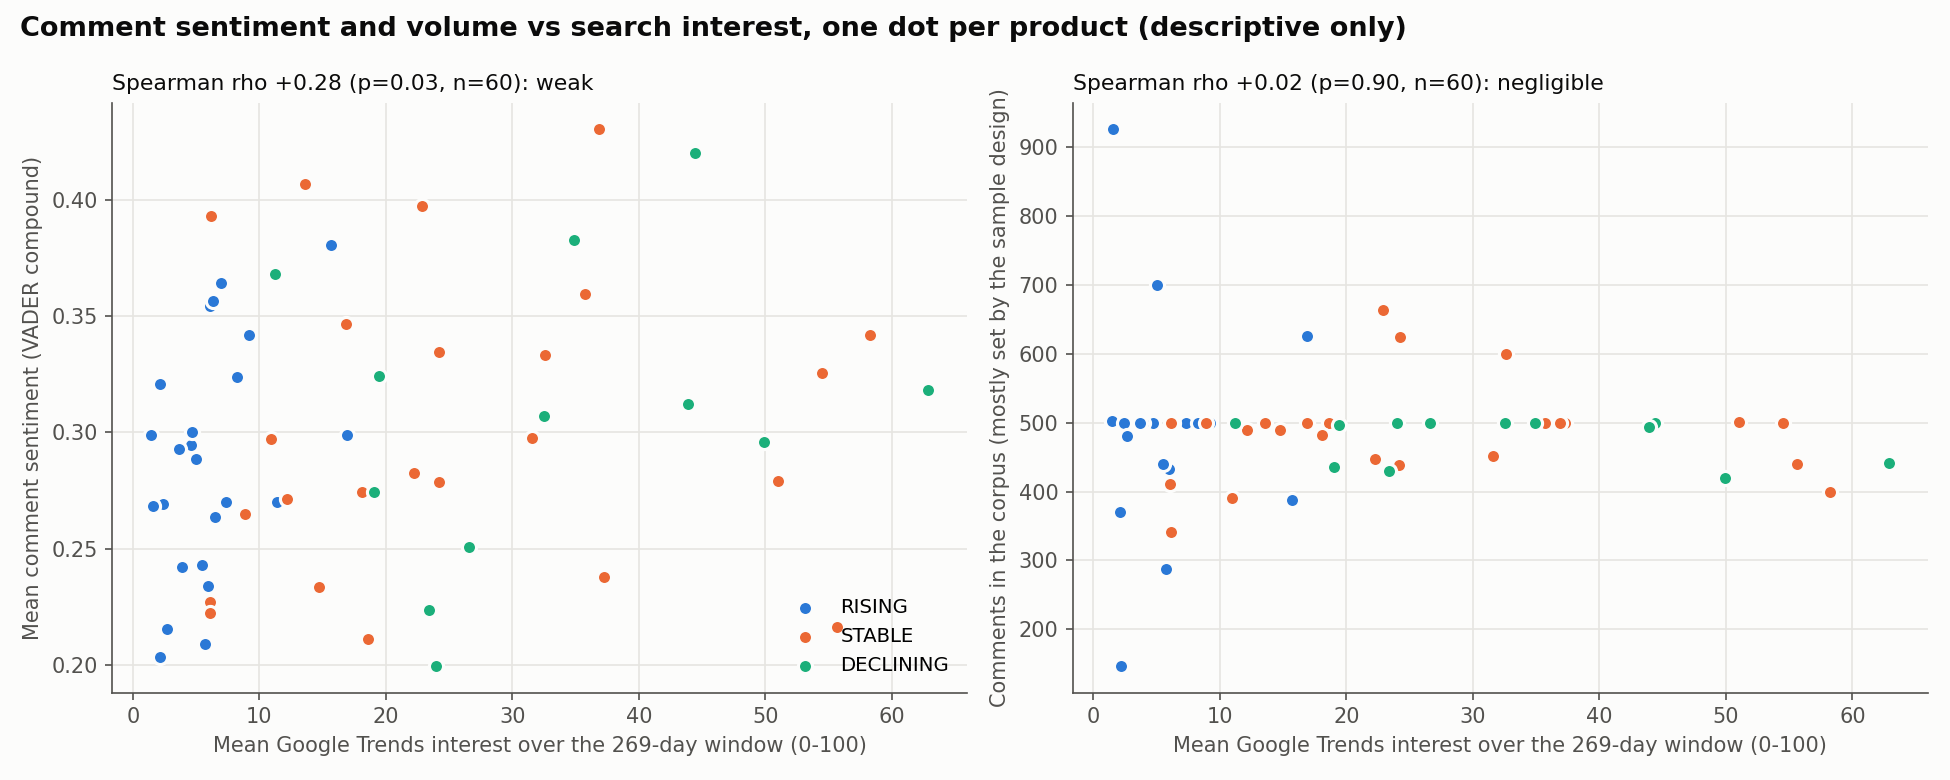

**Finding:** Mean sentiment and mean search interest: Spearman rho +0.28 (p = 0.03, n = 60), weak. Comment volume: rho +0.02, negligible. Neither says what drives demand.

In [8]:
display(Image(FIG / "text_sentiment_vs_interest.png"))
row = link[(link["text_measure"] == "mean_compound") & (link["trends_measure"] == "mean_interest")].iloc[0]
vol = link[(link["text_measure"] == "comments") & (link["trends_measure"] == "mean_interest")].iloc[0]
finding(f"Mean sentiment and mean search interest: Spearman rho {row['spearman_rho']:+.2f} "
        f"(p = {row['spearman_p']:.2f}, n = {int(row['n_products'])}), {row['strength_spearman']}. "
        f"Comment volume: rho {vol['spearman_rho']:+.2f}, {vol['strength_spearman']}. Neither says what drives demand.")

## 8. Correlation table

In [9]:
link.round(3)

,text_measure,trends_measure,n_products,pearson_r,pearson_p,spearman_rho,spearman_p,strength_spearman
0,mean_compound,mean_interest,60,0.214,0.101,0.276,0.033,weak
1,mean_compound,last_7d_mean,60,-0.028,0.834,0.060,0.648,negligible
2,like_weighted_mean_compound,mean_interest,60,0.025,0.851,0.027,0.838,negligible
3,like_weighted_mean_compound,last_7d_mean,60,-0.005,0.967,0.017,0.896,negligible
4,comments,mean_interest,60,-0.028,0.829,0.016,0.904,negligible
5,comments,last_7d_mean,60,-0.332,0.010,-0.152,0.246,weak
